# Regressão linear: prazo até o fechamento

Datas de cadastro ausentes são sintéticas; o fechamento é aproximado pela atualização. O teste usa cadastros originais.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Dados

As exportações são combinadas por referência do imóvel e finalidade. Chaves ausentes ou ambíguas não fornecem correspondências válidas. As datas de cadastro disponíveis são preservadas; as ausentes são geradas com prazos de 30 a 365 dias antes da atualização, usando semente fixa. A auditoria apresenta a quantidade de registros por origem da data.

In [2]:
from pathlib import Path
raiz = Path.cwd()
if not (raiz / "data/raw/imoveis.csv").exists():
    raiz = raiz.parent
arquivo_status = raiz / "data/raw/imoveis.csv"
arquivo_datas = raiz / "data/raw/lima_imoveis/imoveis.csv"
status = pd.read_csv(arquivo_status, sep=None, engine="python", encoding="cp1252", dtype=str)
datas = pd.read_csv(arquivo_datas, sep=None, engine="python", dtype=str)
chaves = ["Referência", "Finalidade"]
for tabela in (status, datas):
    for coluna in chaves:
        tabela[coluna] = tabela[coluna].str.strip().replace("", pd.NA)
validos_status = status.dropna(subset=chaves)
validos_datas = datas.dropna(subset=chaves)
duplicados_status = validos_status.duplicated(chaves, keep=False)
duplicados_datas = validos_datas.duplicated(chaves, keep=False)
base = validos_status.loc[~duplicados_status].merge(
    validos_datas.loc[~duplicados_datas, chaves + ["Data Cadastro"]],
    on=chaves, how="left", validate="one_to_one",
)
base["inicio"] = pd.to_datetime(base["Data Cadastro"], format="%d/%m/%Y", errors="coerce")
base["fim_proxy"] = pd.to_datetime(base["Atualizado em"], format="%d/%m/%Y %H:%M", errors="coerce")
base["dias"] = (base.fim_proxy - base.inicio).dt.days
fechado = (base.Disponibilidade.eq("Alugado") & base.Finalidade.eq("Locação")) | (
    base.Disponibilidade.eq("Vendido") & base.Finalidade.eq("Venda"))

MOCKAR_CADASTRO = True
SEMENTE_MOCK = 42
DIAS_MOCK_MIN = 30
DIAS_MOCK_MAX = 365
assert 0 <= DIAS_MOCK_MIN <= DIAS_MOCK_MAX
base["inicio_original"] = base["inicio"].copy()
base["cadastro_sintetico"] = False
sem_inicio_antes = int((fechado & base.inicio.isna()).sum())
if MOCKAR_CADASTRO:
    mascara_mock = fechado & base.inicio.isna() & base.fim_proxy.notna()

    indices = base.loc[mascara_mock].sort_values(chaves).index
    rng = np.random.default_rng(SEMENTE_MOCK)
    dias_mock = rng.integers(DIAS_MOCK_MIN, DIAS_MOCK_MAX + 1, size=len(indices))
    base.loc[indices, "inicio"] = (
        base.loc[indices, "fim_proxy"].dt.normalize() - pd.to_timedelta(dias_mock, unit="D")
    )
    base.loc[indices, "cadastro_sintetico"] = True
base["origem_data_cadastro"] = np.where(base.cadastro_sintetico, "Sintética", "Original")
base["dias"] = (base.fim_proxy - base.inicio).dt.days
assert base.loc[base.inicio_original.notna(), "inicio"].equals(
    base.loc[base.inicio_original.notna(), "inicio_original"]
)
elegivel = fechado & base.inicio.notna() & base.fim_proxy.notna() & base.dias.ge(0)
auditoria = pd.Series({
    "Linhas na exportação de status": len(status),
    "Linhas de status com chave ausente": int(status[chaves].isna().any(axis=1).sum()),
    "Linhas de status com chave repetida excluídas": int(duplicados_status.sum()),
    "Linhas da exportação de datas com chave repetida excluídas": int(duplicados_datas.sum()),
    "Fechados com status compatível com finalidade": int(fechado.sum()),
    "Fechados sem início válido após cruzamento": sem_inicio_antes,
    "Fechados sem atualização válida": int((fechado & base.fim_proxy.isna()).sum()),
    "Fechados com duração negativa": int((fechado & base.dias.lt(0)).sum()),
    "Cadastros sintéticos gerados": int(base.cadastro_sintetico.sum()),
    "Fechados elegíveis": int(elegivel.sum()),
}, name="quantidade")
display(auditoria)
display(pd.crosstab(base.loc[elegivel, "Finalidade"], base.loc[elegivel, "origem_data_cadastro"]))
base_modelo = base.loc[elegivel].copy()

Linhas na exportação de status                                467
Linhas de status com chave ausente                              2
Linhas de status com chave repetida excluídas                   2
Linhas da exportação de datas com chave repetida excluídas      2
Fechados com status compatível com finalidade                  96
Fechados sem início válido após cruzamento                     76
Fechados sem atualização válida                                 0
Fechados com duração negativa                                   0
Cadastros sintéticos gerados                                   76
Fechados elegíveis                                             96
Name: quantidade, dtype: int64

origem_data_cadastro,Original,Sintética
Finalidade,,
Locação,12,73
Venda,8,3


## Configuração

A finalidade seleciona o mercado analisado, sem misturar valores de venda e locação. As entradas incluem valor do anúncio, dormitórios, banheiros, garagens, tipo e bairro. Os valores correspondem à exportação e podem diferir dos existentes na publicação.

In [3]:
FINALIDADE = "Locação"
MAE_MAXIMO_DIAS = 20
numericas = ["valor_anuncio", "dormitorios", "banheiros", "garagens"]
categoricas = ["tipo", "bairro"]
features = numericas + categoricas

## Preparação

O alvo é a diferença em dias entre cadastro e atualização dos imóveis com status de fechamento compatível com a finalidade. Preços e características são convertidos em campos numéricos. A origem da data de cadastro identifica registros sintéticos e não é usada como entrada do modelo.

In [4]:
fechados = base_modelo.loc[base_modelo.Finalidade.eq(FINALIDADE)].copy()
fechados = fechados.rename(columns={"Referência": "referencia_id", "Tipo": "tipo", "Bairro": "bairro", "dias": "dias_ate_fechamento"})
preco = fechados["Valor"].str.replace("R$", "", regex=False).str.replace(".", "", regex=False).str.replace(",", ".", regex=False).str.strip()
fechados["valor_anuncio"] = pd.to_numeric(preco, errors="coerce")
for coluna, padrao in {
    "dormitorios": r"(\d+)\s+dormitório",
    "banheiros": r"(\d+)\s+banheiro",
    "garagens": r"(\d+)\s+garage",
}.items():
    fechados[coluna] = pd.to_numeric(fechados["Características"].str.extract(padrao, expand=False), errors="coerce")
for coluna in categoricas:
    fechados[coluna] = fechados[coluna].fillna("Não informado")
if len(fechados) < 8:
    raise ValueError("Poucos registros para este exercício: obtenha mais histórico para a finalidade escolhida.")
assert fechados.referencia_id.is_unique
assert fechados.dias_ate_fechamento.ge(0).all()
print("Finalidade:", FINALIDADE, "— registros elegíveis:", len(fechados))
display(fechados["dias_ate_fechamento"].describe())

Finalidade: Locação — registros elegíveis: 85


count     85.000000
mean     220.529412
std      128.565676
min       44.000000
25%      146.000000
50%      202.000000
75%      290.000000
max      781.000000
Name: dias_ate_fechamento, dtype: float64

## Treino e teste

O teste recebe 25% dos registros com cadastro original. O treino reúne os registros originais restantes e os registros com cadastro sintético. A separação usa sorteio fixo e não compartilha imóveis entre os conjuntos. O fechamento é aproximado pela atualização em ambos.

In [5]:
from sklearn.model_selection import train_test_split
originais = fechados.loc[~fechados.cadastro_sintetico].copy()
sinteticos = fechados.loc[fechados.cadastro_sintetico].copy()
if len(originais) < 8:
    raise ValueError("Poucos registros originais para manter um teste separado neste exercício.")
treino_original, teste = train_test_split(originais, test_size=0.25, random_state=42)
treino = pd.concat([treino_original, sinteticos], ignore_index=True)
assert not teste.cadastro_sintetico.any()
assert set(treino.referencia_id).isdisjoint(teste.referencia_id)
if treino[features].isna().all().any():
    raise ValueError("Há variável inteiramente ausente no treino; revise as entradas.")
X_treino, y_treino = treino[features], treino["dias_ate_fechamento"]
X_teste, y_teste = teste[features], teste["dias_ate_fechamento"]
print(f"Treino: {len(treino)} ({len(treino_original)} originais + {len(sinteticos)} sintéticos)")
print(f"Teste: {len(teste)} com cadastro original e fechamento aproximado")

Treino: 82 (9 originais + 73 sintéticos)
Teste: 3 com cadastro original e fechamento aproximado


## Regressão linear

O pipeline reúne o tratamento das entradas e a regressão. Valores numéricos ausentes são preenchidos pela mediana do treino, e categorias são convertidas em colunas numéricas. O ajuste ocorre em `modelo.fit(...)`; `modelo.predict(...)` calcula as previsões do teste.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

preparacao = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("categoricas", Pipeline([
        ("ausencias", SimpleImputer(strategy="most_frequent")),
        ("categorias", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), categoricas),
])

modelo = Pipeline([
    ("preparacao", preparacao),
    ("regressao", LinearRegression()),
])
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
print("Regressão linear treinada.")

Regressão linear treinada.


## Avaliação

**MAE** é o erro absoluto médio em dias. **RMSE** também é expresso em dias e dá maior peso aos erros grandes. Valores menores indicam previsões mais próximas dos prazos observados. A mediana do treino funciona como referência simples para comparação com a regressão. As métricas usam somente o conjunto de teste.

In [7]:
referencia = np.full(len(y_teste), y_treino.median())
linhas = []
for nome, pred in {"Mediana do treino": referencia, "Regressão linear": previsoes}.items():
    linhas.append({
        "metodo": nome,
        "MAE_dias": mean_absolute_error(y_teste, pred),
        "RMSE_dias": np.sqrt(mean_squared_error(y_teste, pred)),
    })
comparacao = pd.DataFrame(linhas)
display(comparacao)
analise_erros = teste[["referencia_id", "tipo", "bairro", "origem_data_cadastro"]].copy()
analise_erros["dias_reais_aproximados"] = y_teste.to_numpy()
analise_erros["dias_previstos"] = previsoes
analise_erros["erro_absoluto"] = np.abs(y_teste.to_numpy() - previsoes)
display(analise_erros.sort_values("erro_absoluto", ascending=False))

,metodo,MAE_dias,RMSE_dias
0,Mediana do treino,324.500000,376.909693
1,Regressão linear,363.879108,387.602821


,referencia_id,tipo,bairro,origem_data_cadastro,dias_reais_aproximados,dias_previstos,erro_absoluto
14,682,Salão Comercial,Vila Santana,Original,323.0,-143.385453,466.385453
192,ALL12,Casa em Condomínio,Jardim Residencial Tivoli Park,Original,781.0,331.037802,449.962198
188,AL8852,Apartamento,Parque Campolim,Original,462.0,286.710326,175.289674


## Gráficos

No primeiro gráfico, pontos próximos da diagonal indicam previsões próximas dos dias observados. No segundo, os resíduos correspondem aos dias observados menos os previstos: valores positivos indicam subestimação do prazo, e valores negativos indicam superestimação. Os dias observados usam a atualização como aproximação do fechamento.

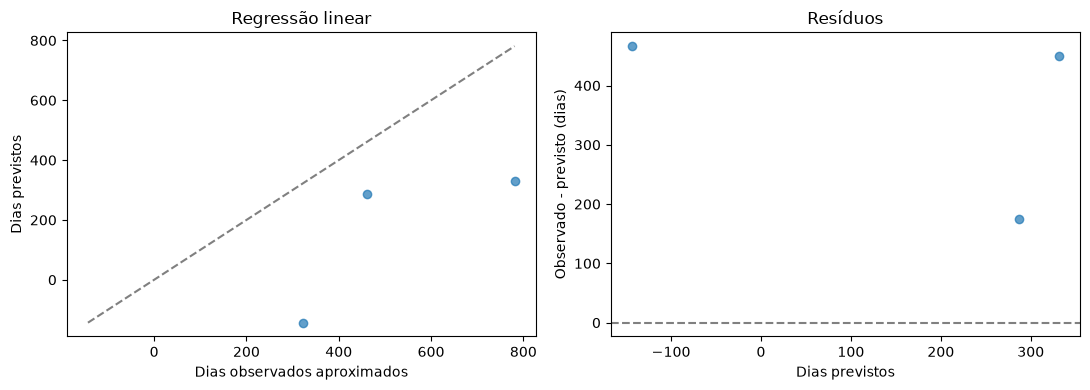

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
inferior = min(float(y_teste.min()), float(previsoes.min()), 0)
superior = max(float(y_teste.max()), float(previsoes.max()), 1)
axes[0].scatter(y_teste, previsoes, alpha=0.7)
axes[0].plot([inferior, superior], [inferior, superior], "--", color="gray")
axes[0].set(title="Regressão linear", xlabel="Dias observados aproximados", ylabel="Dias previstos")
axes[1].scatter(previsoes, y_teste.to_numpy() - previsoes, alpha=0.7)
axes[1].axhline(0, linestyle="--", color="gray")
axes[1].set(title="Resíduos", xlabel="Dias previstos", ylabel="Observado - previsto (dias)")
fig.tight_layout()
plt.show()
plt.close(fig)

## Previsão

O exemplo utiliza as mesmas características e unidades do treino. O resultado representa o prazo estimado entre cadastro e atualização de um anúncio fechado, para a finalidade selecionada.

In [9]:
novo_anuncio = pd.DataFrame([{
    "valor_anuncio": 2000.0,
    "dormitorios": 2,
    "banheiros": 1,
    "garagens": 1,
    "tipo": "Apartamento",
    "bairro": "Centro",
}])

dias_estimados = float(modelo.predict(novo_anuncio)[0])
print(f"Estimativa de cadastro até atualização: {dias_estimados:.1f} dias")

Estimativa de cadastro até atualização: 188.9 dias
